# PROYECTO DE ANALÍTICA DE DATOS - MACI 2026
**Alumnos:** 
1. Keyden Urbina P.
2. Christian Hardtmann.
3. Francisco Flores.

**Dataset:** Amazon Products Sales Dataset 2025

**Fuente:** https://www.kaggle.com/datasets/ikramshah512/amazon-products-sales-dataset-42k-items-2025?resource=download

### Cómo leer este notebook

Este notebook **limpia** el dataset: toma el CSV original y entrega una tabla con números como números, fechas como fechas, un identificador único por producto (ASIN), una categoría y **sin capturas repetidas**. El diagnóstico que justifica cada decisión está en `data_collection_raw.ipynb`.

**Resultado** (dataset completo): 42.675 filas → **9.472 filas** · 8.641 productos únicos (ASIN) · 16 columnas (18 en la versión con ASIN).

## Etapa 1: Obtener y revisar el dataset a utilizar

**Objetivo:** Revisar el dataset para conocer la naturaleza, tipo y calidad de los datos, evaluando completitud, existencia de datos nulos, inconsistentes, incongruentes, y entender bajo una mirada global el dataset que se va a utilizar.

**Conclusión de la revisión:**

Se revisó el dataset y se pudo observar que:

1. Se compone de 42.675 filas y 16 columnas.

2. Todos los datos son tipo 'str' (cadena). Columnas como 'rating' se esperaría que fuesen datos numéricos.

3. Aparentemente, se pobló el dataset mediante scraping, por lo que incrementa el riesgo de error por la extracción.

### Paso 1 -- Se importan las librerías y se definen las carpetas del proyecto

**Qué hace:** carga las "cajas de herramientas" que usaremos y define dónde están los archivos.
- `pandas` → manejar tablas · `numpy` → cálculos · `matplotlib` → gráficos · `re` → buscar patrones en texto (expresiones regulares) · `Path` → rutas de carpetas.
- `BASE` es la carpeta raíz del proyecto. Si el notebook se abre desde la subcarpeta `notebooks/`, sube un nivel; así funciona desde ambos lugares.
- Crea `data/procesado/` y `figuras/` si no existen.

In [1]:
%matplotlib inline
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

print("¡Librerías importadas y validadas con éxito!")
print(f"- Pandas versión: {pd.__version__}")
print(f"- NumPy versión: {np.__version__}")

# Rutas del proyecto (funciona desde notebooks/ o desde la raíz)
BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = BASE / "data" / "raw"
PROCESADO = BASE / "data" / "procesado"
FIGURAS = BASE / "figuras"
for carpeta in (PROCESADO, FIGURAS):
    carpeta.mkdir(parents=True, exist_ok=True)
print(f"\nRaíz del proyecto: {BASE}")

¡Librerías importadas y validadas con éxito!
- Pandas versión: 3.1.0
- NumPy versión: 2.5.4

Raíz del proyecto: /Users/keydenurbina/Desktop/github/Proyecto de Analítica de Datos


### Paso 2 -- Se cargan los datos del archivo CSV

**Qué hace:** lee el archivo CSV original (sin limpiar) y lo deja en la tabla `df`. `df.head()` muestra las primeras 5 filas para tener una idea de cómo vienen los datos.

In [2]:
df = pd.read_csv(RAW / "amazon_products_sales_data_uncleaned.csv")
print(f"Dataset cargado: {df.shape[0]:,} filas | {df.shape[1]} columnas")
df.head()

Dataset cargado: 42,675 filas | 16 columnas


,title,rating,number_of_reviews,bought_in_last_month,current/discounted_price,price_on_variant,listed_price,is_best_seller,is_sponsored,is_couponed,buy_box_availability,delivery_details,sustainability_badges,image_url,product_url,collected_at
0,BOYA BOYALINK 2 Wireless Lavalier Microphone f...,4.6 out of 5 stars,375,300+ bought in past month,89.68,basic variant price: 2.4GHz,$159.00,No Badge,Sponsored,Save 15% with coupon,Add to cart,"Delivery Mon, Sep 1",Carbon impact,https://m.media-amazon.com/images/I/71pAqiVEs3...,/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxND...,2025-08-21 11:14:29
1,"LISEN USB C to Lightning Cable, 240W 4 in 1 Ch...",4.3 out of 5 stars,"2,457",6K+ bought in past month,9.99,basic variant price: nan,$15.99,No Badge,Sponsored,No Coupon,Add to cart,"Delivery Fri, Aug 29",NaN,https://m.media-amazon.com/images/I/61nbF6aVIP...,/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxND...,2025-08-21 11:14:29
2,"DJI Mic 2 (2 TX + 1 RX + Charging Case), Wirel...",4.6 out of 5 stars,"3,044",2K+ bought in past month,314.00,basic variant price: nan,$349.00,No Badge,Sponsored,No Coupon,Add to cart,"Delivery Mon, Sep 1",NaN,https://m.media-amazon.com/images/I/61h78MEXoj...,/sspa/click?ie=UTF8&spc=MTo4NzEzNDY2NTQ5NDYxND...,2025-08-21 11:14:29
3,"Apple AirPods Pro 2 Wireless Earbuds, Active N...",4.6 out of 5 stars,"35,882",10K+ bought in past month,NaN,basic variant price: $162.24,No Discount,Best Seller,Organic,No Coupon,NaN,NaN,NaN,https://m.media-amazon.com/images/I/61SUj2aKoE...,/Apple-Cancellation-Transparency-Personalized-...,2025-08-21 11:14:29
4,Apple AirTag 4 Pack. Keep Track of and find Yo...,4.8 out of 5 stars,"28,988",10K+ bought in past month,NaN,basic variant price: $72.74,No Discount,No Badge,Organic,No Coupon,NaN,NaN,NaN,https://m.media-amazon.com/images/I/61bMNCeAUA...,/Apple-MX542LL-A-AirTag-Pack/dp/B0D54JZTHY/ref...,2025-08-21 11:14:29


### Paso 3 -- Se revisa el tamaño del dataset y la estructura de los datos

**Qué hace:**
- Cuenta filas, columnas y memoria usada.
- **Completitud global** = % de celdas que tienen dato sobre el total de celdas (filas × columnas).
- Arma una tabla con, para cada columna, su tipo de dato y cuántas celdas tienen valor. Se ordena de la más vacía a la más completa.

In [3]:
filas, columnas = df.shape
print(f"Filas: {filas:,} | Columnas: {columnas}")
print(f"Memoria: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print(f"Completitud global: {df.notnull().sum().sum() / df.size * 100:.2f}%\n")

estructura = pd.DataFrame({
    "tipo": df.dtypes,
    "no_nulos": df.notnull().sum(),
    "% no_nulos": (df.notnull().mean() * 100).round(2),
}).sort_values("% no_nulos")
display(estructura)

Filas: 42,675 | Columnas: 16
Memoria: 41.22 MB
Completitud global: 87.59%



,tipo,no_nulos,% no_nulos
sustainability_badges,str,3408,7.99
buy_box_availability,str,28022,65.66
current/discounted_price,str,30926,72.47
delivery_details,str,30955,72.54
bought_in_last_month,str,39458,92.46
product_url,str,40606,95.15
rating,str,41651,97.60
number_of_reviews,str,41651,97.60
title,str,42675,100.00
price_on_variant,str,42675,100.00


## Etapa 2: Diagnóstico de calidad de datos (inicial)

**Objetivo:** Revisar el dataset para conocer en profundidad la calidad de los datos, evaluando si es viable su uso para realizar el modelo e identificar la necesidad de limpieza, transformación o eliminación de la data que se requiera.

**Conclusión de la revisión:**

Se revisó el dataset y se pudo observar que:

1. En el dataset hay 84.723 celdas vacías (nulos reales) y otras 21.031 "ocultas" (ver punto 9), en total 105.754. Las columnas más afectadas son sustainability_badges (39.267 nulos - 92,01%), buy_box_availability (14.653 - 34,34%), current/discounted_price (11.749 - 27,53%) y delivery_details (11.720 - 27,46%). En cambio, rating y number_of_reviews están casi completas (97,6%) y bought_in_last_month (7,54%) y product_url (4,85%) tienen pocos vacíos.

2. Se observa que existe completitud de un 87,6% en todo el dataset (84,5% si se descuentan los nulos ocultos).

3. El dataset contiene 42.675 registros, sin duplicados exactos. Sin embargo, solo el 5,1% de las filas (2.175) está completo, por lo que eliminar todos los registros con valores faltantes implicaría perder el 94,9% de la información; esta alternativa se descarta.

4. La distribución de nulos por fila no es aleatoria. El 49,7% de los registros (21.203) presenta un único valor faltante y, en el 99,3% de esos casos, el vacío está en [sustainability_badges]. Se propone eliminar esta variable en lugar de las filas afectadas, lo que permite recuperar como completos a la mayoría de esos registros.

5. El 23,1% de los registros (9.846) tiene cuatro valores faltantes; en 9.616 de ellos (97,7%) son siempre las mismas cuatro variables: [current/discounted_price], [buy_box_availability], [delivery_details] y [sustainability_badges]. Esto sugiere un segmento de productos con características distintas (por ejemplo, sin oferta activa) más que un error de captura. Este grupo se tratará de forma diferenciada.

6. Finalmente, los 942 registros con cinco o más valores faltantes (2,2%) se eliminarán, al no contener información suficiente para ser imputados.

7. Tipos de datos inconsistentes en formato. Las 16 columnas se almacenan como 'str', por lo que no existe una estructura numérica o temporal tipada que permita analizar fácilmente la data.

8. Los datos numéricos vienen con formato de texto. El rating se registra como "4.6 out of 5 stars", los precios con signos y separadores de miles, y las reseñas mezclan dos formatos. Sin conversión, no es posible calcular promedios, correlaciones ni entrenar modelos.

9. Existen nulos que no se ven. El 49,3% de price_on_variant contiene el texto "nan", que pandas cuenta como dato válido. Un análisis sin revisión habría reportado 0% de nulos en esa variable.

10. En cinco variables el vacío indica ausencia del atributo: 71,2% de productos sin descuento, 95,6% sin distintivo, 95,4% sin cupón, 34,3% sin botón de compra y 92% sin sello sustentable. Estos valores se codificarán como "no tiene", no se imputarán, ya que hacerlo crearía información falsa.

11. Hay un segmento de productos no disponibles. El 27,5% de los registros carece a la vez de precio actual y de fecha de entrega. El patrón coincidente apunta a productos sin opción de compra y no a fallas aleatorias de captura.

12. El mismo producto aparece varias veces. No hay filas idénticas, pero 42.675 registros corresponden a 8.808 títulos. Tratar cada fila como un producto distinto sobrestimaría el catálogo casi cinco veces. Tampoco hay un atributo key que permita identificar al producto. Se esperaría obtenerlo con la URL. La ausencia de un identificador explícito de producto y de una categoría comercial requiere evaluar la unicidad de los registros y la disponibilidad de variables explicativas.

13. Se detectaron formatos mezclados en cinco variables, residuos de HTML, cupones que combinan montos en $ y en %, y nombres de variables que no reflejan su contenido (is_best_seller tiene 12 categorías, no un sí/no). Esto pudo ser producto del scraping.

Finalmente, tras la revisión el riesgo por inconsistencias en formatos, naturaleza de los datos, atributos poco explicativos y problemas de integridad es crítico. Todo esto justifica la necesidad de implementar una etapa de depuración, estandarización y validación de datos antes de aplicar algoritmos de clasificación.

### Paso 4 -- Revisión de datos nulos

**Qué hace:** cuenta, por columna, dos tipos de vacíos:
- **Nulos reales:** la celda está vacía.
- **Nulos ocultos:** la celda *tiene* texto, pero ese texto significa "no hay dato". Puede ser la celda completa (`"nan"`, `"-"`, `"n/a"`…) o una palabra dentro del texto (`"basic variant price: nan"`). Pandas no los cuenta como vacíos, por eso hay que buscarlos con un patrón de texto.

Al final suma ambos (`% total`), revisa si hay filas duplicadas exactas y muestra ejemplos de los nulos ocultos encontrados para confirmar que realmente son vacíos.

In [4]:
FALSOS_NULOS = ["", " ", "na", "n/a", "nan", "null", "none", "-", "--", "?", "sin dato"]  # celda completa = vacío
PATRON_NULO_TEXTO = r"\b(?:nan|null|none|n/a)\b"                                         # palabra 'vacía' dentro del texto

def marcas_de_vacio(serie):
    # Devuelve dos columnas Verdadero/Falso: ¿la celda entera es un vacío? ¿o lo contiene dentro?
    s = serie.dropna().astype(str).str.strip()
    exacto = s.str.lower().isin(FALSOS_NULOS)
    en_texto = s.str.contains(PATRON_NULO_TEXTO, case=False, regex=True) & ~exacto
    return s, exacto, en_texto

marcas = {col: marcas_de_vacio(df[col]) for col in df.columns}   # se calcula una sola vez por columna
nulos = pd.DataFrame({"nulos": df.isnull().sum(), "% nulos": (df.isnull().mean() * 100).round(2)})
nulos["ocultos_exactos"] = [exacto.sum() for _, exacto, _ in marcas.values()]
nulos["ocultos_en_texto"] = [en_texto.sum() for _, _, en_texto in marcas.values()]
nulos["nulos_ocultos"] = nulos["ocultos_exactos"] + nulos["ocultos_en_texto"]
nulos["% ocultos"] = (nulos["nulos_ocultos"] / len(df) * 100).round(2)
nulos["% total"] = nulos["% nulos"] + nulos["% ocultos"]

dup_total = df.duplicated().sum()   # filas 100% idénticas a otra
display(nulos.sort_values("% total", ascending=False))
print(f"Filas duplicadas exactas: {dup_total:,} ({dup_total / len(df) * 100:.2f}%)")

print("\nEjemplos de nulos ocultos por columna:")
for col in nulos.index[nulos["nulos_ocultos"] > 0]:
    s, exacto, en_texto = marcas[col]
    print(f"- {col}: {s[exacto | en_texto].value_counts().head(3).to_dict()}")

,nulos,% nulos,ocultos_exactos,ocultos_en_texto,nulos_ocultos,% ocultos,% total
sustainability_badges,39267,92.01,0,0,0,0.00,92.01
price_on_variant,0,0.00,0,21031,21031,49.28,49.28
buy_box_availability,14653,34.34,0,0,0,0.00,34.34
current/discounted_price,11749,27.53,0,0,0,0.00,27.53
delivery_details,11720,27.46,0,0,0,0.00,27.46
bought_in_last_month,3217,7.54,0,0,0,0.00,7.54
product_url,2069,4.85,0,0,0,0.00,4.85
rating,1024,2.40,0,0,0,0.00,2.40
number_of_reviews,1024,2.40,0,0,0,0.00,2.40
title,0,0.00,0,0,0,0.00,0.00


Filas duplicadas exactas: 0 (0.00%)

Ejemplos de nulos ocultos por columna:
- price_on_variant: {'basic variant price: nan': 21031}


**¿Los vacíos se agrupan en las mismas filas?** Para cada fila se cuenta cuántas columnas tiene vacías y cuáles son. Luego, para las filas con 1 y con 4 vacíos (los grupos más grandes), se muestra:
1. las combinaciones de columnas vacías más frecuentes, y
2. cuántas veces aparece vacía cada columna dentro del grupo.

Si siempre se repite la misma combinación, el vacío no es azar: indica un tipo de producto (por ejemplo, sin oferta activa).

In [5]:
vacias = df.isnull()                                   # tabla Verdadero/Falso: ¿celda vacía?
nulos_por_fila = vacias.sum(axis=1)                    # n° de columnas vacías en cada fila
cols_vacias = pd.Series([", ".join(df.columns[f]) for f in vacias.to_numpy()], index=df.index)

for n in [1, 4]:
    grupo = nulos_por_fila == n
    print(f"\n=== Filas con {n} nulo(s): {grupo.sum():,} ===")
    combinaciones = cols_vacias[grupo].value_counts().head(5)
    display(pd.DataFrame({"filas": combinaciones,
                          "% del grupo": (combinaciones / grupo.sum() * 100).round(1)}))
    print("Columnas vacías más frecuentes en este grupo:")
    print(vacias[grupo].sum().loc[lambda s: s > 0].sort_values(ascending=False).to_string())


=== Filas con 1 nulo(s): 21,203 ===


,filas,% del grupo
sustainability_badges,21059,99.3
bought_in_last_month,86,0.4
buy_box_availability,30,0.1
product_url,17,0.1
current/discounted_price,10,0.0


Columnas vacías más frecuentes en este grupo:
sustainability_badges       21059
bought_in_last_month           86
buy_box_availability           30
product_url                    17
current/discounted_price       10
delivery_details                1

=== Filas con 4 nulo(s): 9,846 ===


,filas,% del grupo
"current/discounted_price, buy_box_availability, delivery_details, sustainability_badges",9616,97.7
"rating, number_of_reviews, bought_in_last_month, sustainability_badges",227,2.3
"bought_in_last_month, buy_box_availability, delivery_details, sustainability_badges",1,0.0
"rating, number_of_reviews, buy_box_availability, sustainability_badges",1,0.0
"rating, number_of_reviews, sustainability_badges, product_url",1,0.0


Columnas vacías más frecuentes en este grupo:
sustainability_badges       9846
buy_box_availability        9618
delivery_details            9617
current/discounted_price    9616
rating                       229
number_of_reviews            229
bought_in_last_month         228
product_url                    1


**Gráficos de nulos.** Cada gráfico se muestra y además se guarda como imagen PNG en `figuras/`. La función `mostrar_y_guardar` evita repetir esas mismas tres líneas en cada gráfico.
- **Gráfico 1:** % de vacíos por columna (rojo = reales, rosado = ocultos). La línea punteada marca el 40%: sobre ese umbral una columna suele eliminarse o transformarse.
- **Gráfico 2:** dona con la proporción de celdas con dato vs. vacías en todo el dataset.
- **Gráfico 3:** cuántas filas tienen 0, 1, 2… columnas vacías.

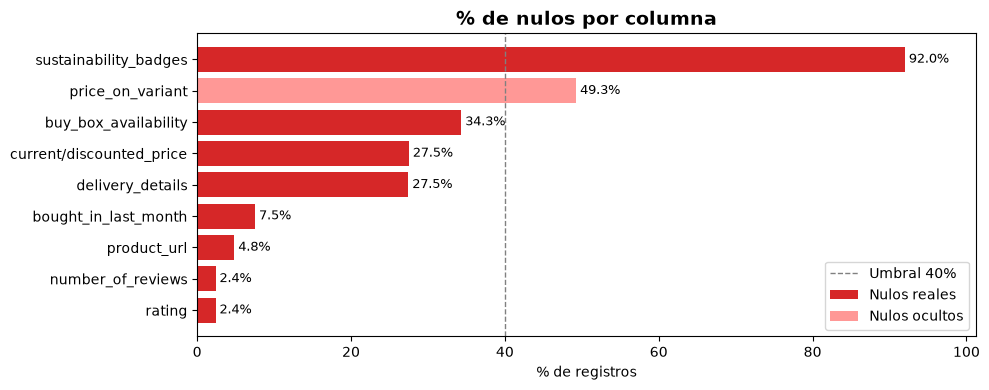

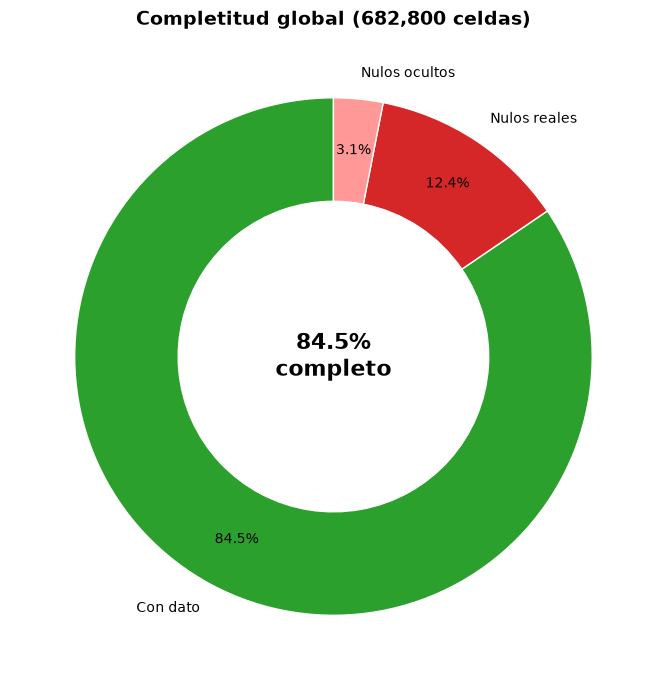

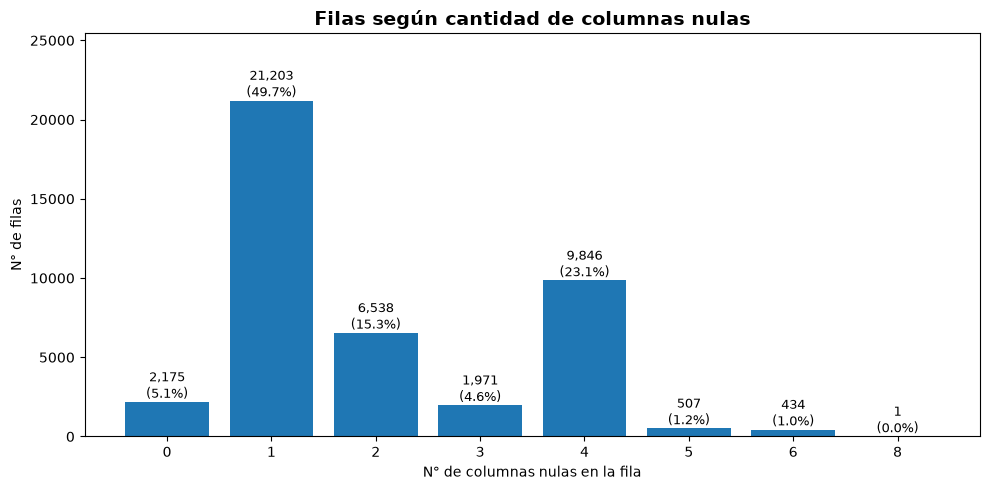


Gráficos guardados en: /Users/keydenurbina/Desktop/github/Proyecto de Analítica de Datos/figuras


In [6]:
def mostrar_y_guardar(fig, nombre):
    plt.tight_layout()
    fig.savefig(FIGURAS / nombre, dpi=200, bbox_inches="tight")
    display(fig)
    plt.close(fig)

# GRÁFICO 1: % DE NULOS POR COLUMNA
g1 = nulos[nulos["% total"] > 0].sort_values("% total")
fig, ax = plt.subplots(figsize=(10, max(4, len(g1) * 0.4)))
ax.barh(g1.index, g1["% nulos"], color="#d62728", label="Nulos reales")
ax.barh(g1.index, g1["% ocultos"], left=g1["% nulos"], color="#ff9896", label="Nulos ocultos")
for i, v in enumerate(g1["% total"]):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9)
ax.axvline(40, color="gray", linestyle="--", linewidth=1, label="Umbral 40%")
ax.set_xlabel("% de registros")
ax.set_xlim(0, max(100, g1["% total"].max() * 1.1))
ax.legend(loc="lower right")
ax.set_title("% de nulos por columna", fontsize=14, fontweight="bold")
mostrar_y_guardar(fig, "01_nulos_por_columna.png")

# GRÁFICO 2: COMPLETITUD GLOBAL
celdas_nulas = df.isnull().sum().sum()
celdas_ocultas = nulos["nulos_ocultos"].sum()
celdas_ok = df.size - celdas_nulas - celdas_ocultas
fig, ax = plt.subplots(figsize=(7, 7))
ax.pie([celdas_ok, celdas_nulas, celdas_ocultas],
       labels=["Con dato", "Nulos reales", "Nulos ocultos"],
       colors=["#2ca02c", "#d62728", "#ff9896"],
       autopct=lambda p: f"{p:.1f}%" if p > 0 else "",
       startangle=90, pctdistance=0.8, wedgeprops={"width": 0.4, "edgecolor": "white"})
ax.text(0, 0, f"{celdas_ok / df.size * 100:.1f}%\ncompleto", ha="center", va="center", fontsize=16, fontweight="bold")
ax.set_title(f"Completitud global ({df.size:,} celdas)", fontsize=14, fontweight="bold")
mostrar_y_guardar(fig, "02_completitud_global.png")

# GRÁFICO 3: FILAS SEGÚN CANTIDAD DE COLUMNAS NULAS
nulos_fila = nulos_por_fila.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 5))
barras = ax.bar(nulos_fila.index.astype(str), nulos_fila.values, color="#1f77b4")
for b, v in zip(barras, nulos_fila.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / len(df) * 100:.1f}%)", ha="center", va="bottom", fontsize=9)
ax.set_title("Filas según cantidad de columnas nulas", fontsize=14, fontweight="bold")
ax.set_xlabel("N° de columnas nulas en la fila")
ax.set_ylabel("N° de filas")
ax.set_ylim(0, nulos_fila.max() * 1.2)
mostrar_y_guardar(fig, "03_nulos_por_fila.png")

print(f"\nGráficos guardados en: {FIGURAS}")

### Paso 5 -- Revisión de duplicados

**Qué hace:** grafica cuántas filas son únicas y cuántas son copia exacta de otra (el conteo se calculó en el Paso 4). Ojo: "sin duplicados exactos" no significa "sin productos repetidos" (ver conclusión 12).

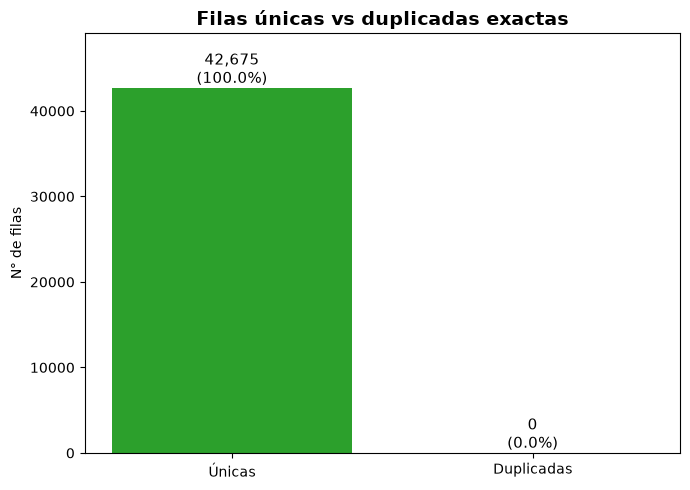

In [7]:
# GRÁFICO 4: FILAS ÚNICAS VS DUPLICADAS
unicas = len(df) - dup_total
fig, ax = plt.subplots(figsize=(7, 5))
barras = ax.bar(["Únicas", "Duplicadas"], [unicas, dup_total], color=["#2ca02c", "#d62728"])
for b, v in zip(barras, [unicas, dup_total]):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / len(df) * 100:.1f}%)", ha="center", va="bottom", fontsize=11)
ax.set_title("Filas únicas vs duplicadas exactas", fontsize=14, fontweight="bold")
ax.set_ylabel("N° de filas")
ax.set_ylim(0, len(df) * 1.15)
mostrar_y_guardar(fig, "04_duplicados.png")

### Paso 6 -- Revisión de inconsistencias en los datos (formatos y estructuras)

**Qué hace:** recorre cada columna y "adivina" qué tipo de dato debería ser (número, fecha, sí/no, categoría, texto, URL), qué problemas de formato tiene y qué hacer con ella. Funciona con pistas simples:
- **Firma de formato:** reemplaza letras por `A` y números por `9`. Así `"$1,299.00"` y `"$15.99"` tienen la misma firma (`$9,9.9` / `$9.9`) y se ve rápido cuántos formatos distintos conviven en una columna.
- **¿Se puede leer como número?** Primero tal cual; luego quitando texto, símbolos y aplicando `K` = mil, `M` = millón.
- **Ausencias:** textos que empiezan con "No…" o "Sin…" (ej. "No Coupon") no son vacíos: significan "no tiene el atributo".

In [9]:
VALORES_BOOL = {"true", "false", "yes", "no", "si", "sí", "y", "n", "t", "f",
                "1", "0", "1.0", "0.0", "verdadero", "falso"}
# Palabras completas de meses y días (evita que "month" coincida con "mon")
PATRON_FECHA_TEXTO = (r"\b(?:jan(?:uary)?|feb(?:ruary)?|mar(?:ch)?|apr(?:il)?|may|june?|july?|"
                      r"aug(?:ust)?|sep(?:t(?:ember)?)?|oct(?:ober)?|nov(?:ember)?|dec(?:ember)?|"
                      r"mon(?:day)?|tue(?:s(?:day)?)?|wed(?:nesday)?|thu(?:rs(?:day)?)?|"
                      r"fri(?:day)?|sat(?:urday)?|sun(?:day)?|"
                      r"ene|abr|ago|dic|lun|mié|jue|vie|sáb|dom)\b")
PATRON_AUSENCIA = r"^(?:no|sin)\b"

def firma(valor):
    "Patrón de formato: letras→A, números→9. Ej: '$1,299.00' → '$9,9.9'"
    return re.sub(r"\d+", "9", re.sub(r"[^\W\d_]+", "A", valor))

def extraer_numero(s):
    "Primer número del texto, sin separador de miles y aplicando sufijo K/M."
    m = s.str.extract(r"(-?\d[\d,]*\.?\d*)\s*([KkMm])?\b")
    num = pd.to_numeric(m[0].str.replace(",", "", regex=False), errors="coerce")
    return num * m[1].str.upper().map({"K": 1_000, "M": 1_000_000}).fillna(1)

def analizar_columna(nombre, serie):
    n = len(serie)
    crudo = serie.dropna().astype(str)
    s = crudo.str.strip()
    unicos = serie.nunique()
    r = {"tipo_actual": str(serie.dtype),
         "% nulos": round(serie.isna().mean() * 100, 1),
         "únicos": unicos,
         "% únicos": round(unicos / n * 100, 1)}
    if len(s) == 0:
        r.update(tipo_inferido="Vacía", acción="Eliminar columna", problemas="100% nulos")
        return r

    # --- 1. Señales de tipo (qué % de valores "parece" URL, fecha, sí/no, número...) ---
    pct_url = s.str.match(r"^(?:https?://|www\.|/)").mean()
    pct_fecha_iso = s.str.match(r"^\d{4}[-/]\d{1,2}[-/]\d{1,2}").mean()
    pct_fecha_txt = s.str.contains(PATRON_FECHA_TEXTO, case=False, regex=True).mean()
    pct_bool = s.str.lower().isin(VALORES_BOOL).mean()

    es_nulo_txt = s.str.contains(PATRON_NULO_TEXTO, case=False, regex=True)
    es_ausencia = s.str.match(PATRON_AUSENCIA, case=False)
    validos = s[~es_nulo_txt & ~es_ausencia]
    pct_validos = len(validos) / len(s)

    num_directo = pd.to_numeric(s, errors="coerce").notna().mean()
    numeros = extraer_numero(validos) if len(validos) else pd.Series(dtype=float)
    num_limpio = numeros.notna().mean() if len(validos) else 0
    es_entero = bool((numeros.dropna() % 1 == 0).all()) if numeros.notna().any() else False

    # Esqueleto de letras: si casi no varía es número con formato; si varía mucho es texto libre
    esqueleto = s.str.lower().str.replace(r"[\d\W_]+", " ", regex=True).str.strip()
    n_esq = esqueleto.nunique()
    ratio_txt = n_esq / s.nunique()
    pct_umbral = validos.str.contains(r"\d\s*[KkMm]?\s*\+").mean() if len(validos) else 0
    multi_num = (s.str.count(r"\d+(?:[.,]\d+)*") > 1).mean()
    largo = s.str.len()

    # --- 2. Tipo inferido (tipo DESTINO) y acción: la primera regla que se cumple gana ---
    if unicos == 1:
        tipo, accion = (("Binario", "Convertir a bool: valor → True, nulo → False") if r["% nulos"] > 0
                        else ("Constante", "Eliminar: no aporta información"))
    elif pct_url >= 0.9:
        tipo, accion = "URL", "Excluir del análisis o extraer identificador"
    elif pct_fecha_iso >= 0.9:
        tipo, accion = "Fecha", "Convertir a datetime"
    elif pct_fecha_txt >= 0.6:
        tipo, accion = "Fecha", "Extraer fecha del texto con regex y convertir a datetime"
    elif unicos == 2 or (pct_bool >= 0.95 and unicos <= 3):
        tipo, accion = "Binario", "Convertir a bool"
    elif num_directo >= 0.95:
        tipo = "Entero" if es_entero else "Decimal"
        accion = "OK" if serie.dtype.kind in "if" else f"Convertir a {'int' if es_entero else 'float'}"
    elif ratio_txt > 0.5 and n_esq > 50:
        tipo, accion = "Texto", "Usar como descripción; revisar repetidos por esta columna"
    elif num_limpio >= 0.8 and pct_validos >= 0.2:
        if pct_umbral >= 0.5:
            tipo, accion = "Ordinal (umbral)", "Extraer número (× K/M) y tratar como categoría ordenada"
        else:
            tipo = "Entero" if es_entero else "Decimal"
            accion = f"Limpiar texto/símbolos y convertir a {'int' if es_entero else 'float'}"
    elif unicos <= 50:
        tipo, accion = "Categórico", "Normalizar texto y convertir a category"
    elif r["% únicos"] >= 90:
        tipo, accion = "Identificador", "Usar como clave; revisar repetidos"
    else:
        tipo, accion = "Texto", "Revisar: agrupar o extraer información"

    # --- 3. Consistencia de formato ---
    firmas = s.map(firma).value_counts(normalize=True)
    simbolos = s.str.findall(r"[^\w\s]").explode().dropna().value_counts().head(4)
    r.update({
        "% nulos ocultos": round(es_nulo_txt.mean() * 100, 1),
        "% ausencia ('No…')": round(es_ausencia.mean() * 100, 1),
        "% num directo": round(num_directo * 100, 1),
        "% num tras limpiar": round(num_limpio * 100, 1),
        "n° formatos": len(firmas),
        "formato dominante": f"{firmas.index[0][:40]} ({firmas.iloc[0]*100:.0f}%)",
        "símbolos": ", ".join(f"{k}:{v:,}" for k, v in simbolos.items()) or "-",
        "largo min–max": f"{largo.min()}–{largo.max()}",
        "ejemplos": " | ".join(s.value_counts().index[:3].str[:30]),
    })

    # --- 4. Problemas detectados ---
    p = []
    espacios = int((crudo != s).sum())
    variantes = s.nunique() - s.str.lower().nunique()
    if r["% nulos"] > 40: p.append("nulos >40%: eliminar o convertir a presencia (bool)")
    if es_nulo_txt.any(): p.append(f"{es_nulo_txt.mean()*100:.1f}% nulos ocultos en el texto")
    if es_ausencia.any(): p.append(f"{es_ausencia.mean()*100:.1f}% 'No…' = ausencia del atributo, no nulo")
    if espacios: p.append(f"{espacios:,} con espacios sobrantes")
    if s.str.contains(r"&nbsp;|\xa0|&amp;|\s{2,}").any(): p.append("espacios dobles / restos HTML")
    if variantes: p.append(f"{variantes:,} variantes mayúsc./minúsc.")
    if firmas.iloc[0] < 0.9 and len(firmas) > 1 and tipo not in ("Texto", "URL"):
        p.append("formatos mezclados")
    if nombre.lower().startswith("is_") and unicos > 2:
        p.append(f"nombre sugiere booleano pero tiene {unicos} categorías")
    if tipo in ("Entero", "Decimal", "Ordinal (umbral)"):
        if num_directo < 1 and num_limpio > num_directo:
            p.append(f"{(1 - num_directo)*100:.0f}% requiere limpiar símbolos/separadores")
        if s.str.contains(r"\d\s*[KkMm]\b").any(): p.append("sufijos K/M")
        if multi_num > 0.05: p.append("más de un número por valor: se toma el primero")
        if s.str.contains(r"\$").any() and s.str.contains("%").any(): p.append("mezcla $ y %: separar tipo y monto")
    r["problemas"] = "; ".join(p) or "-"
    r.update(tipo_inferido=tipo, acción=accion)
    return r

**Tabla resumen por columna.** `TIPOS_MANUALES` permite que el analista corrija la sugerencia automática (columna `origen` = "Manual"). Aquí se decidió dejar `bought_in_last_month` como texto.

In [10]:
TIPOS_MANUALES = {
    "bought_in_last_month": ("Texto", "Mantener como texto (decisión del analista)"),
}
pd.set_option("display.max_colwidth", 70)

resumen = pd.DataFrame({col: analizar_columna(col, df[col]) for col in df.columns}).T
resumen["tipo_final"] = resumen["tipo_inferido"]
resumen["origen"] = "Automático"
for col, (tipo, accion) in TIPOS_MANUALES.items():
    resumen.loc[col, ["tipo_final", "acción", "origen"]] = [tipo, accion, "Manual"]

orden = ["tipo_actual", "tipo_inferido", "tipo_final", "origen", "acción", "problemas",
         "% nulos", "% nulos ocultos", "% ausencia ('No…')", "únicos", "% únicos",
         "% num directo", "% num tras limpiar", "n° formatos", "formato dominante",
         "símbolos", "largo min–max", "ejemplos"]
resumen = resumen[orden]
display(resumen)

print("\nVariables por tipo final:")
print(resumen["tipo_final"].value_counts().to_string())

,tipo_actual,tipo_inferido,tipo_final,origen,acción,problemas,% nulos,% nulos ocultos,% ausencia ('No…'),únicos,% únicos,% num directo,% num tras limpiar,n° formatos,formato dominante,símbolos,largo min–max,ejemplos
title,str,Texto,Texto,Automático,Usar como descripción; revisar repetidos por esta columna,1 variantes mayúsc./minúsc.,0.0,0.0,0.0,8808,20.6,0.0,91.4,7544,A 9 A A A A ($9 - $9.9) (4%),",:112,578, -:74,281, (:22,154, ):22,082",12–255,"Duracell Coppertop 9V Battery, | Energizer MAX AA Batteries (16 | ..."
rating,str,Decimal,Decimal,Automático,Limpiar texto/símbolos y convertir a float,100% requiere limpiar símbolos/separadores; más de un número por v...,2.4,0.0,0.0,31,0.1,0.0,100.0,1,9.9 A A 9 A (100%),".:41,651",18–18,4.6 out of 5 stars | 4.4 out of 5 stars | 4.5 out of 5 stars
number_of_reviews,str,Entero,Entero,Automático,Limpiar texto/símbolos y convertir a int,formatos mezclados; 37% requiere limpiar símbolos/separadores,2.4,0.0,0.0,4413,10.3,63.3,100.0,2,9 (63%),",:15,272",1–7,25 | 1 | 8
bought_in_last_month,str,Ordinal (umbral),Texto,Manual,Mantener como texto (decisión del analista),"11.6% 'No…' = ausencia del atributo, no nulo; formatos mezclados; ...",7.5,0.0,11.6,59,0.1,0.0,92.4,15,9+ A A A A (70%),"+:32,165, ::1,689, .:757, ’:524",4–172,100+ bought in past month | 50+ bought in past month | 200+ bought...
current/discounted_price,str,Decimal,Decimal,Automático,Convertir a float,4% requiere limpiar símbolos/separadores,27.5,0.0,0.0,2576,6.0,96.1,100.0,2,9.9 (96%),".:30,926, ,:1,192",4–8,29.99 | 119.99 | 13.99
price_on_variant,str,Decimal,Decimal,Automático,Limpiar texto/símbolos y convertir a float,49.3% nulos ocultos en el texto; formatos mezclados; 100% requiere...,0.0,49.3,0.0,3466,8.1,0.0,98.4,25,A A A: A (50%),"::42,675, .:20,105, $:20,071, (:939",23–47,basic variant price: nan | basic variant price: 16 Count | basic ...
listed_price,str,Decimal,Decimal,Automático,Limpiar texto/símbolos y convertir a float,"71.2% 'No…' = ausencia del atributo, no nulo; formatos mezclados; ...",0.0,0.0,71.2,911,2.1,0.0,100.0,3,A A (71%),"$:12,311, .:12,311, ,:638",5–11,No Discount | $79.99 | $29.99
is_best_seller,str,Categórico,Categórico,Automático,Normalizar texto y convertir a category,"95.6% 'No…' = ausencia del atributo, no nulo; nombre sugiere boole...",0.0,0.0,95.6,12,0.0,0.0,18.1,4,A A (97%),"':744, %:336",7–17,No Badge | Amazon's | Limited time deal
is_sponsored,str,Binario,Binario,Automático,Convertir a bool,-,0.0,0.0,0.0,2,0.0,0.0,0.0,1,A (100%),-,7–9,Organic | Sponsored
is_couponed,str,Categórico,Categórico,Automático,Normalizar texto y convertir a category,"95.4% 'No…' = ausencia del atributo, no nulo; espacios dobles / re...",0.0,0.0,95.4,42,0.1,0.0,100.0,4,A A (95%),"%:1,061, $:887, .:887, (:1",9–41,No Coupon | Save $16.00 with coupon | Save 15% with coupon



Variables por tipo final:
tipo_final
Decimal       4
Categórico    3
Texto         2
Binario       2
Fecha         2
URL           2
Entero        1


**Detalle de una columna.** `detalle("nombre_columna")` muestra, para una sola columna: su fila del resumen, los valores más frecuentes, los formatos encontrados (con un ejemplo real de cada uno) y, si es numérica, su rango y los valores que no se pudieron convertir a número. Cambia el nombre entre comillas para revisar otra columna.

In [11]:
def detalle(col, n=10):
    serie = df[col]
    s = serie.dropna().astype(str).str.strip()
    print(f"{'=' * 70}\nCOLUMNA: {col}\n{'=' * 70}")
    display(resumen.loc[[col]].T)

    print("\n1. Valores más frecuentes:")
    display(serie.value_counts(dropna=False).head(n).to_frame("frecuencia"))

    print("\n2. Formatos encontrados (patrón → ejemplo real):")
    firmas = s.map(firma)
    top = firmas.value_counts().head(n)
    display(pd.DataFrame({"filas": top,
                          "%": (top / len(s) * 100).round(1),
                          "ejemplo": [s[firmas == p].iloc[0] for p in top.index]}))

    numeros = extraer_numero(s)
    if numeros.notna().mean() >= 0.5:
        print("\n3. Rango numérico extraído:")
        display(numeros.describe().round(2).to_frame("valor"))
        if numeros.notna().mean() < 1:
            print("\n4. Valores que NO se pueden convertir a número:")
            display(s[numeros.isna()].value_counts().head(n).to_frame("frecuencia"))

detalle("bought_in_last_month")

COLUMNA: bought_in_last_month


,bought_in_last_month
tipo_actual,str
tipo_inferido,Ordinal (umbral)
tipo_final,Texto
origen,Manual
acción,Mantener como texto (decisión del analista)
problemas,"11.6% 'No…' = ausencia del atributo, no nulo; formatos mezclados; ..."
% nulos,7.5
% nulos ocultos,0.0
% ausencia ('No…'),11.6
únicos,59



1. Valores más frecuentes:


,frecuencia
bought_in_last_month,
100+ bought in past month,8801
50+ bought in past month,5967
200+ bought in past month,5645
No featured offers available,4571
NaN,3217
300+ bought in past month,2842
500+ bought in past month,2351
1K+ bought in past month,2084
400+ bought in past month,1436



2. Formatos encontrados (patrón → ejemplo real):


,filas,%,ejemplo
bought_in_last_month,,,
9+ A A A A,27716,70.2,300+ bought in past month
A A A A,4571,11.6,No featured offers available
9A+ A A A A,4448,11.3,6K+ bought in past month
A:,1060,2.7,Typical:
A A A,654,1.7,More Buying Choices
A A:,512,1.3,List Price:
A A A A A A A A A’A A. A A A A A A A A A A A’A A A A A.,262,0.7,Shop products from small business brands sold in Amazon’s store. D...
A A: A,107,0.3,ESRB Rating: Everyone
($9.9$9.9/A),63,0.2,($54.26$54.26/count)



3. Rango numérico extraído:


,valor
count,32233.00
mean,1292.02
std,6311.74
min,2.18
25%,100.00
50%,200.00
75%,400.00
max,100000.00



4. Valores que NO se pueden convertir a número:


,frecuencia
bought_in_last_month,
No featured offers available,4571
More Buying Choices,654
Typical:,532
List:,518
List Price:,511
Shop products from small business brands sold in Amazon’s store. Discover more about the small businesses partnering with Amazon and Amazon’s commitment to empowering them.,262
ESRB Rating: Everyone,107
This product is certified by Amazon to work with Alexa. This product can be controlled with your voice through Alexa-enabled devices such as Amazon Echo and Amazon Tap.,47
Was:,10


In [12]:
for col in df.columns:
    missing_count = df[col].isnull().sum()
    missing_percentage = (missing_count / len(df)) * 100
    print(f"'{col}': {missing_percentage:.2f}%")

'title': 0.00%
'rating': 2.40%
'number_of_reviews': 2.40%
'bought_in_last_month': 7.54%
'current/discounted_price': 27.53%
'price_on_variant': 0.00%
'listed_price': 0.00%
'is_best_seller': 0.00%
'is_sponsored': 0.00%
'is_couponed': 0.00%
'buy_box_availability': 34.34%
'delivery_details': 27.46%
'sustainability_badges': 92.01%
'image_url': 0.00%
'product_url': 4.85%
'collected_at': 0.00%


## Etapa 3: Limpieza y estandarización

| Paso | Columna(s) | Problema | Qué se hace |
|---|---|---|---|
| 3 | `is_sponsored`, `is_couponed` | Texto ("Sponsored", "Save 15% with coupon"…) | 1/0 |
| 4 | precios | Texto con `$` y `,`; 27,5% del precio actual vacío | Número; se rellena con el precio de la variante básica y se calcula el % de descuento |
| 5 | `rating`, `number_of_reviews`, `bought_in_last_month` | `"4.6 out of 5 stars"`, `"2,457"`, `"6K+ bought…"` | Número |
| 6 | `delivery_details`, `collected_at` | Texto | Fecha |
| 7 | *(nueva)* `category` | No existe | Se asigna por palabras clave del título |
| 8 | nombres | Poco claros | Se renombran |
| 9–11 | *(nueva)* `asin` | El identificador está escondido en la URL | Se extrae; los que no tienen URL se completan con ASIN validados a mano |
| 12–13 | filas | 77,8% son la misma ficha capturada varias veces | Se eliminan; se conserva el conteo en `n_capturas` |

`is_best_seller` se deja como texto: tiene 12 valores que mezclan distintivos ("Best Seller", "Amazon's") con descuentos ("Save 30%") y el 95,64% es "No Badge".

### Paso 7 -- Librerías y carpetas del proyecto

In [13]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from urllib.parse import unquote

# Rutas del proyecto (funciona desde notebooks/ o desde la raíz)
BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROCESADO, FIGURAS = BASE / "data" / "raw", BASE / "data" / "procesado", BASE / "figuras"
for carpeta in (PROCESADO, FIGURAS):
    carpeta.mkdir(parents=True, exist_ok=True)

### Paso 8 -- Cargar los datos y crear la copia de trabajo

In [14]:
df = pd.read_csv(RAW / "amazon_products_sales_data_uncleaned.csv")
df1 = df.copy()
print(f"{df.shape[0]:,} filas | {df.shape[1]} columnas | duplicados exactos: {df.duplicated().sum()}")

42,675 filas | 16 columnas | duplicados exactos: 0


### Paso 9 -- Patrocinado y Cupón a 1/0

- `is_sponsored`: "Sponsored" → **1**, "Organic" → **0**.
- `is_couponed`: "No Coupon" → **0**; cualquier cupón → **1** (el monto del cupón no se usa).

El `assert` es un control: si aparece un valor no previsto o un vacío, el notebook se detiene sin modificar nada.

In [15]:
assert set(df1["is_sponsored"]) == {"Sponsored", "Organic"}, "Valores no previstos en is_sponsored"
assert df1["is_couponed"].notna().all(), "Hay vacíos en is_couponed"

df1["is_sponsored"] = df1["is_sponsored"].eq("Sponsored").astype(int)
df1["is_couponed"] = df1["is_couponed"].ne("No Coupon").astype(int)
print(df1[["is_sponsored", "is_couponed"]].mean().mul(100).round(1).astype(str).add("% con 1").to_string())

is_sponsored    16.4% con 1
is_couponed      4.6% con 1


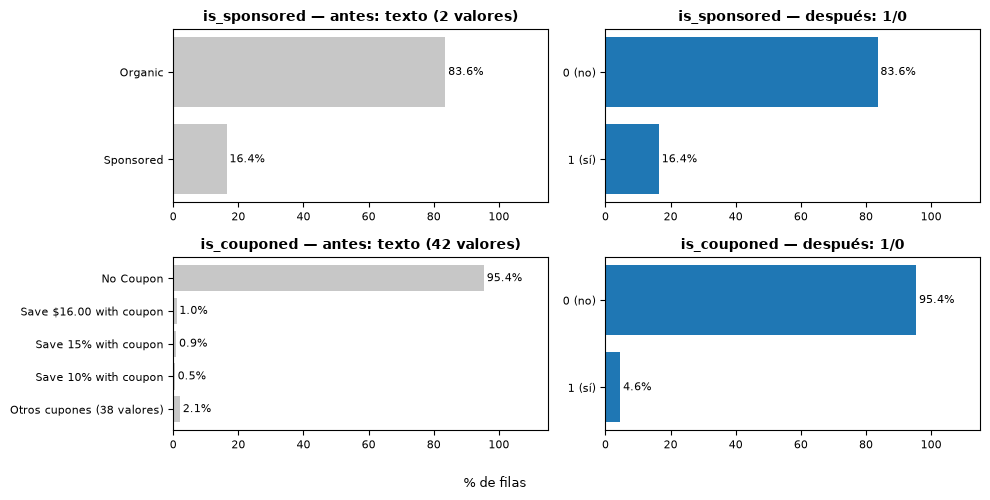

In [16]:
# Gráfico antes / después: texto original (df) vs. 1/0 (df1)
fig, axes = plt.subplots(2, 2, figsize=(10, 5))
for (ax_antes, ax_despues), col in zip(axes, ["is_sponsored", "is_couponed"]):
    antes = df[col].str.replace(r"\s+", " ", regex=True).value_counts(normalize=True) * 100
    n = len(antes)
    if n > 5:                                            # agrupa la cola larga de cupones distintos
        antes = pd.concat([antes.head(4), pd.Series({f"Otros cupones ({n - 4} valores)": antes.iloc[4:].sum()})])
    despues = (df1[col].value_counts(normalize=True) * 100).rename({0: "0 (no)", 1: "1 (sí)"}).sort_index()
    for ax, datos, titulo, color in [(ax_antes, antes, f"{col} — antes: texto ({n} valores)", "#c7c7c7"),
                                     (ax_despues, despues, f"{col} — después: 1/0", "#1f77b4")]:
        ax.barh(datos.index[::-1], datos.values[::-1], color=color)
        ax.bar_label(ax.containers[0], fmt="%.1f%%", fontsize=8, padding=2)
        ax.set_title(titulo, fontsize=10, fontweight="bold")
        ax.set_xlim(0, 115)
        ax.tick_params(labelsize=8)
fig.supxlabel("% de filas", fontsize=9)
plt.tight_layout()
plt.savefig(FIGURAS / "06_binarios_antes_despues.png", dpi=200)
plt.show()

### Paso 10 -- Precios y % de descuento

1. **Precio actual:** donde está vacío se rellena con el precio de la variante básica (`"basic variant price: $162.24"` → `162.24`; si el texto no trae `$`, no es un precio y se ignora). Luego se quitan `$` y `,` y se convierte a número. `price_on_variant` se elimina porque ya cumplió su función.
2. **Precio de lista:** `"No Discount"` no es un número y queda vacío (`errors="coerce"`); en ese caso el precio de lista **es** el precio actual.
3. **% de descuento** = (precio de lista − precio actual) / precio de lista × 100.

In [17]:
a_numero = lambda s: pd.to_numeric(s.str.replace(r"[$,]", "", regex=True).str.strip(), errors="coerce")

variante = df1["price_on_variant"].str.extract(r":\s*(\$[\d,.]+)", expand=False)
df1["current/discounted_price"] = a_numero(df1["current/discounted_price"].fillna(variante))
df1["listed_price"] = a_numero(df1["listed_price"]).fillna(df1["current/discounted_price"])
df1["discount_percentage"] = ((df1["listed_price"] - df1["current/discounted_price"]) / df1["listed_price"] * 100).round(2)
df1 = df1.drop(columns="price_on_variant")
print(df1[["current/discounted_price", "listed_price"]].isna().sum().rename("vacíos").to_string())

current/discounted_price    2062
listed_price                2062


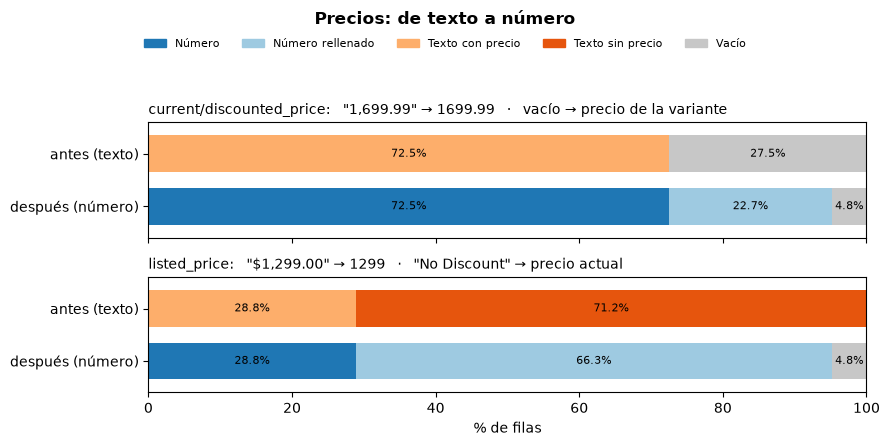

In [18]:
# Gráfico antes / después por variable: el original es TEXTO; el resultado, NÚMERO (cada barra suma 100%)
COLORES = {"Número": "#1f77b4", "Número rellenado": "#9ecae1", "Texto con precio": "#fdae6b",
           "Texto sin precio": "#e6550d", "Vacío": "#c7c7c7"}
RELLENO = {"current/discounted_price": "vacío → precio de la variante", "listed_price": '"No Discount" → precio actual'}
fig, axes = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True)
for ax, col in zip(axes, RELLENO):
    original = a_numero(df[col]).notna()                       # el texto traía un precio legible
    pct = pd.DataFrame({
        "antes (texto)":    {"Texto con precio": original.mean(), "Texto sin precio": (df[col].notna() & ~original).mean(),
                             "Vacío": df[col].isna().mean()},
        "después (número)": {"Número": original.mean(), "Número rellenado": (~original & df1[col].notna()).mean(),
                             "Vacío": df1[col].isna().mean()},
    }).T.reindex(columns=list(COLORES)).fillna(0).iloc[::-1] * 100
    pct.plot.barh(stacked=True, ax=ax, width=0.7, color=COLORES, legend=False)
    for barras, c in zip(ax.containers, pct.columns):
        ax.bar_label(barras, labels=[f"{v:.1f}%" if v >= 3 else "" for v in pct[c]], label_type="center", fontsize=8)
    i = df.loc[original, col].str.len().idxmax()               # ejemplo: el texto más largo que se convirtió
    ax.set_title(f'{col}:   "{df.at[i, col]}" → {df1.at[i, col]:g}   ·   {RELLENO[col]}', fontsize=10, loc="left")
axes[-1].set(xlim=(0, 100), xlabel="% de filas")
fig.suptitle("Precios: de texto a número", fontweight="bold")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORES.values()], COLORES, ncol=5,
           loc="upper center", bbox_to_anchor=(0.5, 0.94), frameon=False, fontsize=8)
plt.tight_layout(rect=(0, 0, 1, 0.88))
plt.savefig(FIGURAS / "07_precios_antes_despues.png", dpi=200)
plt.show()

### Paso 11 -- Calificación, reseñas y compras del último mes a número

- `rating`: `"4.6 out of 5 stars"` → `4.6`
- `number_of_reviews`: `"2,457"` → `2457`
- `bought_in_last_month`: `"6K+ bought in past month"` → `6000`. Solo se aceptan resultados que sean dígitos; textos como "No featured offers available" quedan vacíos. Se guarda como entero que admite vacíos (`Int64`).

In [19]:
df1["rating"] = df1["rating"].str.replace("out of 5 stars", "").astype(float)
df1["number_of_reviews"] = df1["number_of_reviews"].str.replace(",", "").astype(float)
compras = df1["bought_in_last_month"].str.replace("+ bought in past month", "").str.strip().str.replace("K", "000")
df1["bought_in_last_month"] = compras.where(compras.str.isdigit()).astype("Int64")
print(df1[["rating", "number_of_reviews", "bought_in_last_month"]].isna().sum().rename("vacíos").to_string())

rating                   1024
number_of_reviews        1024
bought_in_last_month    10511


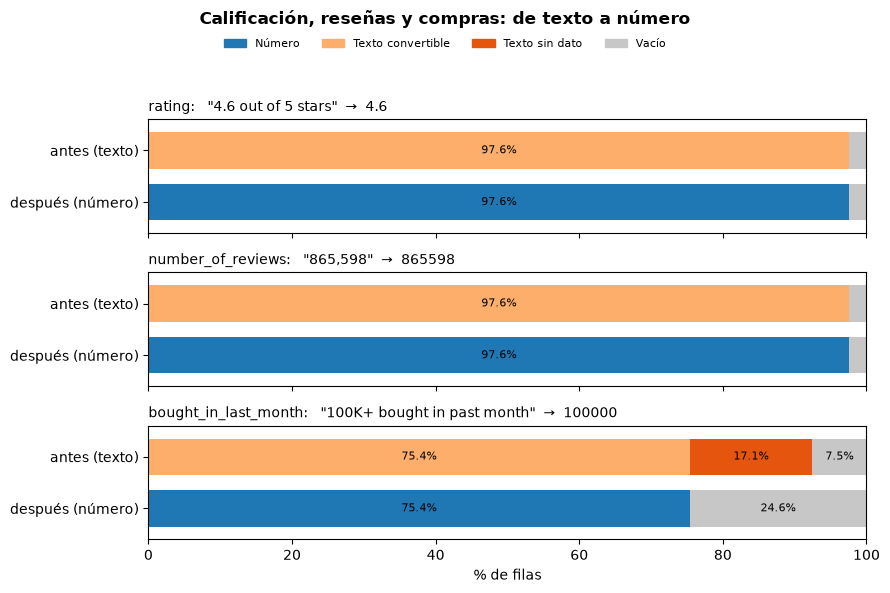

bought_in_last_month
No featured offers available    4571
More Buying Choices              654
Typical:                         532
List:                            518
List Price:                      511


In [20]:
# Gráfico antes / después por variable: el original es TEXTO; el resultado, NÚMERO (cada barra suma 100%)
COLORES = {"Número": "#1f77b4", "Texto convertible": "#fdae6b", "Texto sin dato": "#e6550d", "Vacío": "#c7c7c7"}
fig, axes = plt.subplots(3, 1, figsize=(9, 6), sharex=True)
for ax, col in zip(axes, ["rating", "number_of_reviews", "bought_in_last_month"]):
    valido = df1[col].notna()                                  # quedó como número
    pct = pd.DataFrame({
        "antes (texto)":    {"Texto convertible": valido.mean(), "Texto sin dato": (df[col].notna() & ~valido).mean(),
                             "Vacío": df[col].isna().mean()},
        "después (número)": {"Número": valido.mean(), "Vacío": (~valido).mean()},
    }).T.reindex(columns=list(COLORES)).fillna(0).iloc[::-1] * 100
    pct.plot.barh(stacked=True, ax=ax, width=0.7, color=COLORES, legend=False)
    for barras, c in zip(ax.containers, pct.columns):
        ax.bar_label(barras, labels=[f"{v:.1f}%" if v >= 3 else "" for v in pct[c]], label_type="center", fontsize=8)
    i = df.loc[valido, col].str.len().idxmax()                 # ejemplo: el texto más largo que se convirtió
    ax.set_title(f'{col}:   "{df.at[i, col]}"  →  {df1.at[i, col]:g}', fontsize=10, loc="left")
axes[-1].set(xlim=(0, 100), xlabel="% de filas")
fig.suptitle("Calificación, reseñas y compras: de texto a número", fontweight="bold")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORES.values()], COLORES, ncol=4,
           loc="upper center", bbox_to_anchor=(0.5, 0.95), frameon=False, fontsize=8)
plt.tight_layout(rect=(0, 0, 1, 0.91))
plt.savefig(FIGURAS / "08_rating_reviews_compras_antes_despues.png", dpi=200)
plt.show()

# ¿Qué textos de compras quedaron vacíos?
sin_dato = df["bought_in_last_month"].notna() & df1["bought_in_last_month"].isna()
print(df.loc[sin_dato, "bought_in_last_month"].str[:40].value_counts().head(5).to_string())

### Paso 12 -- Fechas

- `delivery_details`: se busca el primer "mes + día" del texto (`"FREE delivery Thu, Sep 4Or fastest…"` → `Sep 4`), se le agrega 2025 y se convierte a fecha. Sin fecha reconocible → `NaT`.
- `collected_at`: texto → fecha-hora.

In [21]:
fecha = df1["delivery_details"].str.extract(r"(?:Mon|Tue|Wed|Thu|Fri|Sat|Sun)?,?\s*(\w+\s+\d{1,2})", expand=False)
df1["delivery_details"] = pd.to_datetime(fecha + " 2025", format="%b %d %Y", errors="coerce")
df1["collected_at"] = pd.to_datetime(df1["collected_at"])
print(f"Fechas de entrega válidas: {df1['delivery_details'].notna().sum():,}")

Fechas de entrega válidas: 30,692


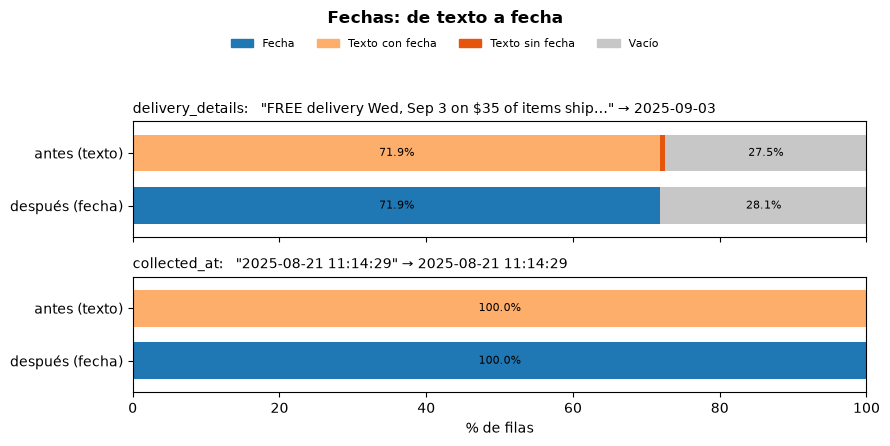

delivery_details
$40.34 delivery    83
$54.46 delivery    39
$41.15 delivery    32
$46.68 delivery    13
FREE delivery      13


In [22]:
# Gráfico antes / después por variable: el original es TEXTO; el resultado, FECHA (cada barra suma 100%)
COLORES = {"Fecha": "#1f77b4", "Texto con fecha": "#fdae6b", "Texto sin fecha": "#e6550d", "Vacío": "#c7c7c7"}
FORMATO = {"delivery_details": "%Y-%m-%d", "collected_at": "%Y-%m-%d %H:%M:%S"}
fig, axes = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True)
for ax, col in zip(axes, FORMATO):
    valido = df1[col].notna()                                  # quedó como fecha
    pct = pd.DataFrame({
        "antes (texto)":   {"Texto con fecha": valido.mean(), "Texto sin fecha": (df[col].notna() & ~valido).mean(),
                            "Vacío": df[col].isna().mean()},
        "después (fecha)": {"Fecha": valido.mean(), "Vacío": (~valido).mean()},
    }).T.reindex(columns=list(COLORES)).fillna(0).iloc[::-1] * 100
    pct.plot.barh(stacked=True, ax=ax, width=0.7, color=COLORES, legend=False)
    for barras, c in zip(ax.containers, pct.columns):
        ax.bar_label(barras, labels=[f"{v:.1f}%" if v >= 3 else "" for v in pct[c]], label_type="center", fontsize=8)
    i = df.loc[valido, col].str.len().idxmax()                 # ejemplo: el texto más largo que se convirtió
    texto = df.at[i, col] if len(df.at[i, col]) <= 45 else df.at[i, col][:45] + "…"
    ax.set_title(f'{col}:   "{texto}" → {df1.at[i, col]:{FORMATO[col]}}', fontsize=10, loc="left")
axes[-1].set(xlim=(0, 100), xlabel="% de filas")
fig.suptitle("Fechas: de texto a fecha", fontweight="bold")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORES.values()], COLORES, ncol=4,
           loc="upper center", bbox_to_anchor=(0.5, 0.94), frameon=False, fontsize=8)
plt.tight_layout(rect=(0, 0, 1, 0.88))
plt.savefig(FIGURAS / "09_fechas_antes_despues.png", dpi=200)
plt.show()

# ¿Qué textos de entrega no traían una fecha?
sin_fecha = df["delivery_details"].notna() & df1["delivery_details"].isna()
print(df.loc[sin_fecha, "delivery_details"].str[:40].value_counts().head(5).to_string())

### Paso 13 -- Categoría por palabras clave del título

El dataset no trae categoría. Para cada título distinto:
1. Lo pasa a minúsculas y cambia los símbolos por espacios (así "High-Performance" no esconde un `hp`).
2. Busca primero en el **núcleo** del título, lo que va antes de "for", "with" o "compatible": es lo que el producto **es** ("Cable … for MacBook" es un cable). Si ahí no encuentra nada, busca en el título completo.
3. Busca **palabras completas**, aceptando plurales (`battery` también encuentra "batteries").
4. Si calzan varias, gana la palabra clave más larga ("watch battery" le gana a "watch"); si empatan, la categoría que aparece primero en el diccionario.
5. Sin coincidencias → "Other Electronics".

`CATEGORIA_MANUAL` corrige por ASIN los productos que las palabras clave no alcanzan (se aplica en el Paso 11).

In [23]:
CATEGORIAS = {   # el ORDEN desempata: de lo más específico a lo más general
    "Services & Subscriptions": ["protection plan", "asurion", "warranty", "applecare", "membership"],
    "Office Supplies":      ["paper", "ink", "toner", "drum unit", "label", "name tag", "name badge", "shredder", "note pad",
                             "notepad", "notebook", "sticky note", "envelope", "binder", "stapler", "wipes", "cleaning kit",
                             "screen cleaner"],
    "Camera Accessories":   ["lens", "tripod", "light stand", "selfie stick", "gimbal", "instant film", "film", "camera bag"],
    "Headphones":           ["headphone", "headset", "earphone", "earbud", "airpods", "buds"],
    "Gaming":               ["playstation", "ps5", "ps4", "xbox", "nintendo switch", "nintendo", "controller", "joystick",
                             "gamepad", "gaming console", "gaming mouse", "gaming keyboard", "gaming chair", "racing wheel"],
    "Computer Accessories": ["mouse", "keyboard", "usb hub", "monitor mount", "monitor arm", "desk mount", "laptop stand",
                             "mouse pad", "stream deck"],
    "Storage":              ["ssd", "hard drive", "hdd", "solid state drive", "external drive", "flash drive", "usb drive",
                             "memory card", "sd card", "micro sd", "microsd", "sdxc", "nas"],
    "Chargers & Cables":    ["charger", "charging cable", "charging station", "cable", "adapter", "power adapter", "dock",
                             "docking station"],
    "Tablets":              ["ipad", "tablet", "tab", "e reader", "kindle", "stylus", "apple pencil"],
    "Wearables":            ["smartwatch", "smart watch", "watch", "fitness tracker", "fitness band", "smart band",
                             "smart ring", "fitbit"],
    "Cameras":              ["camera", "dslr", "mirrorless", "camcorder", "webcam", "gopro", "dash cam", "nest cam",
                             "action cam", "instax"],
    "Power & Batteries":    ["battery", "watch battery", "power bank", "aa", "aaa", "9v", "cr2032", "coin cell",
                             "power station", "surge protector", "power strip", "extension cord", "battery backup"],
    "Phones":               ["phone", "smartphone", "iphone", "cell phone", "galaxy", "screen protector"],
    "Laptops":              ["laptop", "macbook", "chromebook", "ultrabook", "thinkpad", "ideapad"],
    "Computer Components":  ["ddr4", "ddr5", "ram kit", "desktop memory", "motherboard", "graphics card", "gpu",
                             "power supply", "processor", "cpu", "cpu cooler", "capture card"],
    "TV & Display":         ["tv", "television", "monitor", "display", "projector", "digital picture frame", "picture frame",
                             "streaming stick", "streaming device", "blu ray player"],
    "Smart Home":           ["alexa", "echo dot", "echo show", "smart speaker", "smart plug", "smart bulb", "smart home",
                             "nest", "homekit", "video doorbell", "smart lock", "thermostat"],
    "Speakers & Audio":     ["speaker", "soundbar", "subwoofer", "home theater", "amplifier", "amp", "receiver",
                             "microphone", "mic", "turntable"],
    "Networking":           ["router", "modem", "extender", "access point", "ethernet", "network switch", "gigabit",
                             "mesh wifi", "wifi adapter"],
    "Printers & Scanners":  ["printer", "scanner"],
}

def patron(kw):
    "Palabra completa, aceptando plural: battery→batteries, cable→cables, display→displays."
    base = r"\s+".join(map(re.escape, kw.split()))
    base = base[:-1] + "(?:y|ies)" if re.search(r"[^aeiou]y$", kw) else base + "(?:s|es)?"
    return re.compile(rf"\b{base}\b")

# Reglas ordenadas por prioridad: más palabras primero; si empatan, el orden del diccionario
REGLAS = sorted(((len(kw.split()), i, cat, patron(kw)) for i, (cat, kws) in enumerate(CATEGORIAS.items()) for kw in kws),
                key=lambda r: (-r[0], r[1]))

def categorizar(titulo):
    t = re.sub(r"[^a-z0-9]+", " ", titulo.lower()).strip()
    nucleo = re.split(r"\b(?:for|compatible|with|fits|works)\b", t, maxsplit=1)[0]
    for texto in (nucleo, t):
        cat = next((c for _, _, c, rx in REGLAS if rx.search(texto)), None)
        if cat:
            return cat
    return "Other Electronics"

titulos = df1["title"].unique()                                   # se clasifica una vez por título, no por fila
df1["category"] = df1["title"].map(dict(zip(titulos, map(categorizar, titulos))))
print(f"{df1['category'].nunique()} categorías | 'Other Electronics': {df1['category'].eq('Other Electronics').mean():.1%} de las filas")

21 categorías | 'Other Electronics': 8.5% de las filas


21 categorías | 'Other Electronics': 8.5% de las filas


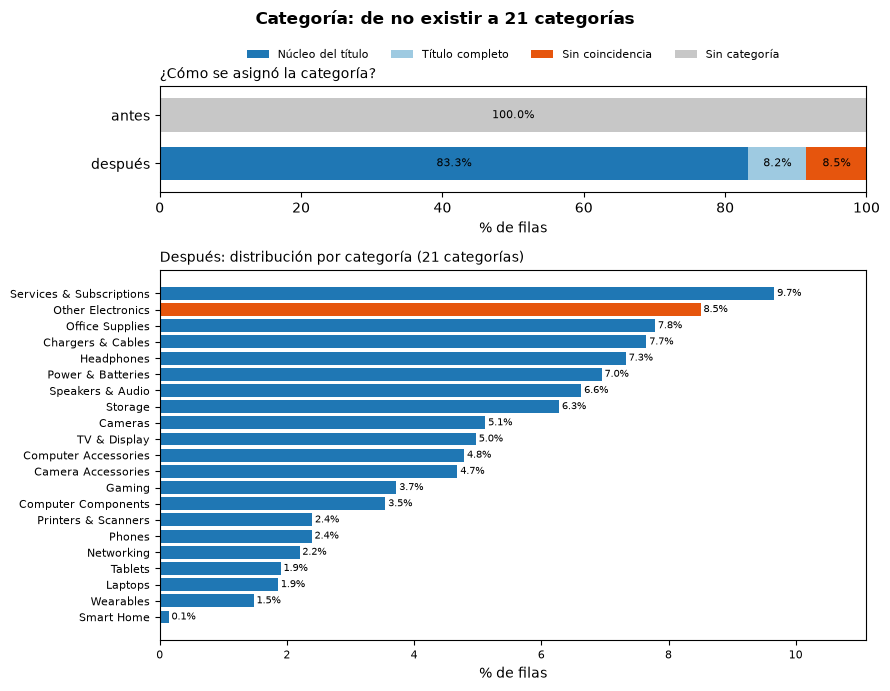

In [24]:
def categorizar(titulo):
    "Devuelve (categoría, parte del título donde se encontró la palabra clave)."
    t = re.sub(r"[^a-z0-9]+", " ", titulo.lower()).strip()
    nucleo = re.split(r"\b(?:for|compatible|with|fits|works)\b", t, maxsplit=1)[0]
    for parte, texto in (("Núcleo del título", nucleo), ("Título completo", t)):
        cat = next((c for _, _, c, rx in REGLAS if rx.search(texto)), None)
        if cat:
            return cat, parte
    return "Other Electronics", "Sin coincidencia"

titulos = df1["title"].unique()                                   # se clasifica una vez por título, no por fila
asignacion = pd.DataFrame(map(categorizar, titulos), index=titulos, columns=["categoria", "parte"])
df1["category"] = df1["title"].map(asignacion["categoria"])
print(f"{df1['category'].nunique()} categorías | 'Other Electronics': {df1['category'].eq('Other Electronics').mean():.1%} de las filas")

# Gráfico antes / después: antes no existía categoría; después, cómo se asignó y cómo se distribuye
COLORES = {"Núcleo del título": "#1f77b4", "Título completo": "#9ecae1", "Sin coincidencia": "#e6550d", "Sin categoría": "#c7c7c7"}
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7), gridspec_kw={"height_ratios": [1, 3.5]})
como = df1["title"].map(asignacion["parte"]).value_counts(normalize=True)
pct = pd.DataFrame({"antes": {"Sin categoría": 1}, "después": como}).T.reindex(columns=list(COLORES)).fillna(0).iloc[::-1] * 100
pct.plot.barh(stacked=True, ax=ax1, width=0.7, color=COLORES, legend=False)
for barras, c in zip(ax1.containers, pct.columns):
    ax1.bar_label(barras, labels=[f"{v:.1f}%" if v >= 3 else "" for v in pct[c]], label_type="center", fontsize=8)
ax1.set(xlim=(0, 100), xlabel="% de filas")
ax1.set_title("¿Cómo se asignó la categoría?", fontsize=10, loc="left")
ax1.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.15), frameon=False, fontsize=8)

dist = df1["category"].value_counts(normalize=True).sort_values() * 100
ax2.barh(dist.index, dist, color=["#e6550d" if c == "Other Electronics" else "#1f77b4" for c in dist.index])
ax2.bar_label(ax2.containers[0], fmt="%.1f%%", fontsize=7, padding=2)
ax2.set(xlim=(0, dist.max() * 1.15), xlabel="% de filas")
ax2.set_title(f"Después: distribución por categoría ({dist.size} categorías)", fontsize=10, loc="left")
ax2.tick_params(labelsize=8)
fig.suptitle(f"Categoría: de no existir a {dist.size} categorías", fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURAS / "10_categoria_antes_despues.png", dpi=200)
plt.show()

### Paso 14 -- Renombrar columnas

In [25]:
df1 = df1.rename(columns={
    "title": "product_title", "rating": "product_rating", "number_of_reviews": "total_reviews",
    "bought_in_last_month": "purchased_last_month", "current/discounted_price": "discounted_price",
    "listed_price": "original_price", "is_couponed": "has_coupon", "delivery_details": "delivery_date",
    "sustainability_badges": "sustainability_tags", "image_url": "product_image_url",
    "product_url": "product_page_url", "collected_at": "data_collected_at", "category": "product_category",
})

### Paso 15 -- Extraer el ASIN desde la URL

En Amazon cada producto tiene un código único de 10 caracteres, el **ASIN** (ej. `B0D54JZTHY`), que va dentro de la URL (`…/dp/B0D54JZTHY/…`). `unquote` "decodifica" las URL de anuncios patrocinados, que traen `/` escrito como `%2F`. Si la URL está vacía o no tiene ese patrón, el ASIN queda vacío.

In [26]:
def extraer_asin(url):
    m = re.search(r"/(?:dp|gp/product)/([A-Z0-9]{10})(?=[/?#]|$)", unquote(url), flags=re.I) if isinstance(url, str) else None
    return m.group(1).upper() if m else pd.NA

df1["asin"] = df1["product_page_url"].map(extraer_asin)
df1["asin_origen"] = df1["asin"].notna().map({True: "URL original", False: pd.NA})
print(f"Filas con ASIN desde la URL: {df1['asin'].notna().sum():,} ({df1['asin'].notna().mean():.1%})")

Filas con ASIN desde la URL: 40,606 (95.2%)


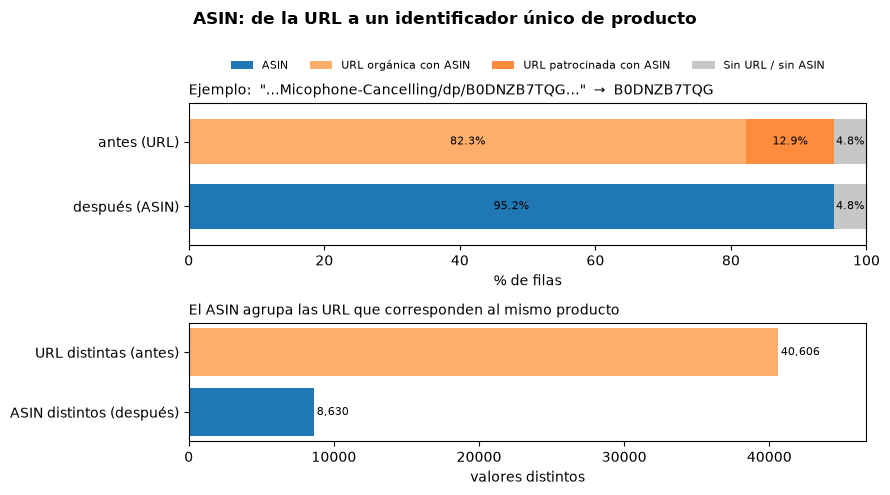

In [27]:
# Gráfico antes / después: de URL (texto largo y distinto en cada captura) a ASIN (10 caracteres por producto)
url, tiene = df["product_url"], df1["asin"].notna()
sspa = url.str.contains("/sspa/", na=False)                     # anuncio patrocinado: la URL viene codificada (%2F)
COLORES = {"ASIN": "#1f77b4", "URL orgánica con ASIN": "#fdae6b", "URL patrocinada con ASIN": "#fd8d3c",
           "URL sin ASIN": "#e6550d", "Sin URL / sin ASIN": "#c7c7c7"}
pct = pd.DataFrame({
    "antes (URL)":  {"URL orgánica con ASIN": (tiene & ~sspa).mean(), "URL patrocinada con ASIN": (tiene & sspa).mean(),
                     "URL sin ASIN": (url.notna() & ~tiene).mean(), "Sin URL / sin ASIN": url.isna().mean()},
    "después (ASIN)": {"ASIN": tiene.mean(), "Sin URL / sin ASIN": (~tiene).mean()},
}).T.reindex(columns=list(COLORES)).fillna(0).iloc[::-1] * 100
pct = pct.loc[:, pct.sum() > 0]                                  # solo las categorías que aparecen

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5), gridspec_kw={"height_ratios": [1.2, 1]})
pct.plot.barh(stacked=True, ax=ax1, width=0.7, color=[COLORES[c] for c in pct], legend=False)
for barras, c in zip(ax1.containers, pct.columns):
    ax1.bar_label(barras, labels=[f"{v:.1f}%" if v >= 3 else "" for v in pct[c]], label_type="center", fontsize=8)
i = (tiene & sspa).idxmax()                                      # ejemplo: una URL patrocinada
k = unquote(url[i]).find("/dp/")
ax1.set(xlim=(0, 100), xlabel="% de filas")
ax1.set_title(f'Ejemplo:  "…{unquote(url[i])[k - 20:k + 14]}…"  →  {df1.at[i, "asin"]}', fontsize=10, loc="left")
ax1.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.15), frameon=False, fontsize=8)

distintos = pd.Series({"URL distintas (antes)": url.nunique(), "ASIN distintos (después)": df1["asin"].nunique()})
ax2.barh(distintos.index[::-1], distintos[::-1], color=["#1f77b4", "#fdae6b"])
ax2.bar_label(ax2.containers[0], fmt="{:,.0f}", fontsize=8, padding=2)
ax2.set(xlim=(0, distintos.max() * 1.15), xlabel="valores distintos")
ax2.set_title("El ASIN agrupa las URL que corresponden al mismo producto", fontsize=10, loc="left")
fig.suptitle("ASIN: de la URL a un identificador único de producto", fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURAS / "11_asin_antes_despues.png", dpi=200)
plt.show()

### Paso 16 -- Incorporar los ASIN validados manualmente en Amazon

`VALIDADOS` registra los ASIN buscados y confirmados a mano para productos sin URL: título exacto, filas esperadas, ASIN, método y estado. Para agregar uno nuevo basta sumar una fila y volver a correr todo.

**Controles:** cada ASIN debe tener 10 caracteres y cada título debe encontrar exactamente las filas esperadas. Si algo no cuadra, el notebook se detiene **antes** de modificar cualquier fila.

In [28]:
VALIDADOS = [
    # (título exacto, filas esperadas, ASIN, método, estado)
    ("CR 2016 MAXELL LITHIUM BATTERIES (2 piece) 3V Watch 2016 New",
     204, "B00IX9OUTM", "Búsqueda externa", "Validado"),
    ("Duracell Coppertop 9V Battery, 6 Count (Pack of 1), 9 Volt Battery with Long-lasting Power, All-Purpose Alkaline 9V Battery for Household and Office Devices",
     744, "B0B72DBKVF", "Verificación externa Amazon", "Validado (ficha actual)"),
    ("Energizer MAX AA Batteries (16 Pack), Double A Alkaline Batteries",
     566, "B004RFF57C", "Verificación externa Amazon", "Validado (ficha actual)"),
    ("Energizer Alkaline Power AAA Batteries, 32 Count, Long-Lasting Triple A Batteries, Suitable for Everyday Electronics and Emergency Gear",
     93, "B09RTVN5GN", "Verificación externa Amazon", "Validado (ficha actual)"),
    ("Renata Watch Battery 321 0%Hg Mercury Free X 3",
     79, "B00NHYB6VI", "Verificación externa Amazon", "Validado (ficha actual)"),
    ("Duracell Precharged Recharg. Battery AA (Pack of 2)",
     79, "B081J2QH83", "Verificación externa Amazon", "Validado (ficha actual)"),
    ("Windex Electronic Cleaning Wipes, Pre-Moistened Screen Wipes for TVs, Phones, and Other Electronics, Resealable for a Freshness Lock, 25 Count (Pack of 3)",
     65, "B072B91QTN", "Verificación externa Amazon", "Validado (ficha actual)"),
    ("Energizer CR2032 Lithium 3V Coin Batteries for Watches, AirTags, Key Fobs, Small Electronics (10 Pack)",
     19, "B0CH1N7X5W", "Verificación externa Amazon", "Validado (ficha actual)"),
    ("Energizer MAX AAA Batteries (16 Pack), Triple A Alkaline Batteries",
     14, "B0D51CSMKX", "Verificación externa Amazon", "Validado (ficha actual)"),
    ("Energizer AA and AAA Batteries, 48 Count, Combo Pack Contains 24 Max Double A and 24 Max Triple A Batteries",
     6, "B087GMJXMC", "Verificación externa Amazon", "Validado (ficha actual)"),
    ("Energizer AA Batteries Alkaline Power, 32 Count Alkaline Double A Battery Pack",
     6, "B09RTVD1GF", "Verificación externa Amazon", "Validado (ficha actual)"),
]
asin_pendientes_validacion = pd.DataFrame(VALIDADOS, columns=["product_title", "registros", "asin_candidato", "metodo", "estado"])
asin_pendientes_validacion.insert(3, "fuente", "https://www.amazon.com/dp/" + asin_pendientes_validacion["asin_candidato"])
assert asin_pendientes_validacion["asin_candidato"].str.fullmatch(r"[A-Z0-9]{10}").all(), "Hay un ASIN mal escrito"

filtros = {}
for v in asin_pendientes_validacion.itertuples():
    filtro = df1["product_title"].eq(v.product_title) & df1["asin"].isna()
    if filtro.sum() != v.registros:
        raise ValueError(f"{v.asin_candidato}: se esperaban {v.registros} filas y hay {filtro.sum()}. No se modificó nada.")
    filtros[v.asin_candidato] = filtro

for asin, filtro in filtros.items():          # solo se escribe si TODOS los controles pasaron
    df1.loc[filtro, ["asin", "asin_origen"]] = [asin, "Validación manual Amazon"]
print(f"Filas completadas a mano: {sum(f.sum() for f in filtros.values()):,} | cobertura de ASIN: {df1['asin'].notna().mean():.1%}")

Filas completadas a mano: 1,875 | cobertura de ASIN: 99.5%


### Paso 17 -- Corrección manual de categoría por ASIN

Para productos que las palabras clave no clasifican bien. Se clasifica un ASIN una vez y la categoría se aplica a todas sus filas. El `assert` detiene el notebook si una categoría está mal escrita.

In [29]:
CATEGORIA_MANUAL = {
    # "ASIN": "Categoría",                   # título (para saber qué es)
    "B0BN4PPQ16": "Computer Components",     # MEM 2 * 16G|GSK F5-6000J3636F16GX2-FX5 (memoria DDR5 G.Skill)
    "B08QLN4ZZN": "Computer Accessories",    # Blackmagic Design DaVinci Resolve Speed Editor
}
assert set(CATEGORIA_MANUAL.values()) <= set(CATEGORIAS) | {"Other Electronics"}, "Categoría mal escrita"
manual = df1["asin"].isin(CATEGORIA_MANUAL)
df1.loc[manual, "product_category"] = df1.loc[manual, "asin"].map(CATEGORIA_MANUAL)
print(f"Filas recategorizadas a mano: {manual.sum():,}")

Filas recategorizadas a mano: 274


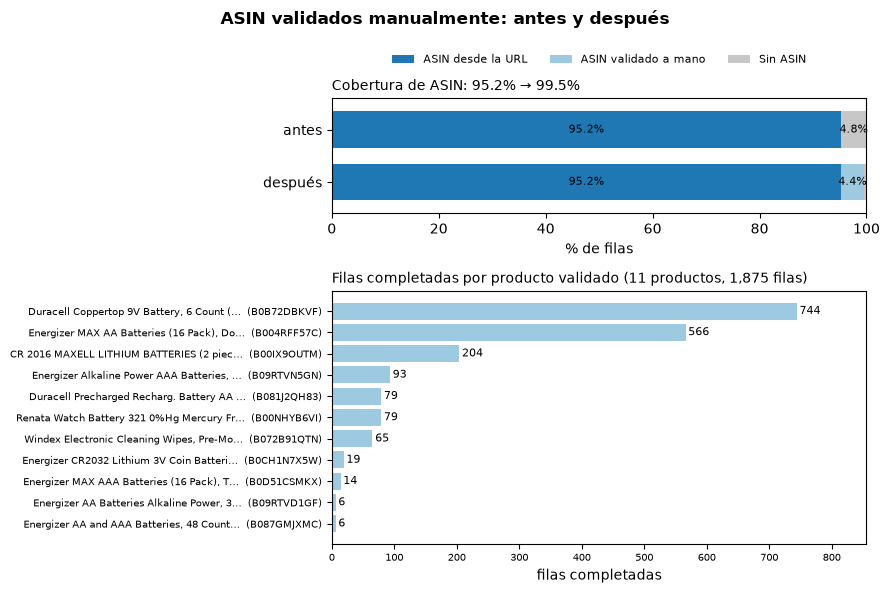

In [30]:
# Gráfico antes / después: cobertura de ASIN y filas completadas por cada producto validado
COLORES = {"ASIN desde la URL": "#1f77b4", "ASIN validado a mano": "#9ecae1", "Sin ASIN": "#c7c7c7"}
desde_url = df1["asin_origen"].eq("URL original")
pct = pd.DataFrame({
    "antes":   {"ASIN desde la URL": desde_url.mean(), "Sin ASIN": (~desde_url).mean()},
    "después": {"ASIN desde la URL": desde_url.mean(), "ASIN validado a mano": df1["asin_origen"].eq("Validación manual Amazon").mean(),
                "Sin ASIN": df1["asin"].isna().mean()},
}).T.reindex(columns=list(COLORES)).fillna(0).iloc[::-1] * 100

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), gridspec_kw={"height_ratios": [1, 2.2]})
pct.plot.barh(stacked=True, ax=ax1, width=0.7, color=COLORES, legend=False)
for barras, c in zip(ax1.containers, pct.columns):
    ax1.bar_label(barras, labels=[f"{v:.1f}%" if v >= 3 else "" for v in pct[c]], label_type="center", fontsize=8)
ax1.set(xlim=(0, 100), xlabel="% de filas")
ax1.set_title(f"Cobertura de ASIN: {desde_url.mean():.1%} → {df1['asin'].notna().mean():.1%}", fontsize=10, loc="left")
ax1.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.2), frameon=False, fontsize=8)

v = asin_pendientes_validacion.sort_values("registros")
ax2.barh(v["product_title"].str[:40] + "…  (" + v["asin_candidato"] + ")", v["registros"], color="#9ecae1")
ax2.bar_label(ax2.containers[0], fmt="{:,.0f}", fontsize=8, padding=2)
ax2.set(xlim=(0, v["registros"].max() * 1.15), xlabel="filas completadas")
ax2.set_title(f"Filas completadas por producto validado ({len(v)} productos, {v['registros'].sum():,} filas)", fontsize=10, loc="left")
ax2.tick_params(labelsize=7)
fig.suptitle("ASIN validados manualmente: antes y después", fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURAS / "12_asin_validados_antes_despues.png", dpi=200)
plt.show()

### Paso 18 -- Diagnóstico de filas repetidas

El dataset no tiene filas 100% idénticas porque cada captura guarda una **URL distinta** (parámetros de búsqueda y seguimiento: hay 40.606 URL distintas para 8.641 productos, y un mismo producto llegó a tener 456) y **su hora** (`data_collected_at`). Al ignorar esas columnas aparece que la mayoría de las filas son la misma ficha capturada varias veces. La fecha de entrega también depende del día de captura ("llega el 1 de septiembre" visto el 25 o el 26 de agosto), así que tampoco describe al producto.

El gráfico muestra, por columna, qué % de filas tiene un valor que se repite en otra fila. Que las columnas categóricas (pocos valores distintos) se repitan es normal; lo relevante es que se repitan las que deberían identificar un producto.

Fila completa                                       0 repetidas (0.0%)
Sin fecha de captura                            1,820 repetidas (4.3%)
Sin fecha ni URL                               32,751 repetidas (76.7%)
Sin fecha, URL, imagen ni fecha de entrega     33,203 repetidas (77.8%)


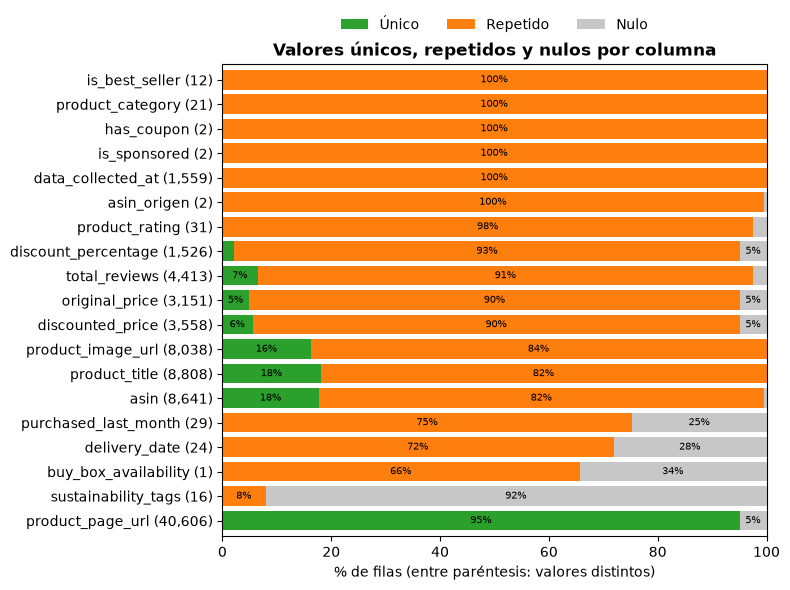

In [31]:
captura = ["data_collected_at", "product_page_url", "product_image_url", "delivery_date"]   # cambian entre capturas
escenarios = {"Fila completa": [], "Sin fecha de captura": captura[:1],
              "Sin fecha ni URL": captura[:2], "Sin fecha, URL, imagen ni fecha de entrega": captura}
for nombre, ignorar in escenarios.items():
    n = df1.duplicated(subset=[c for c in df1.columns if c not in ignorar]).sum()
    print(f"{nombre:<45} {n:>7,} repetidas ({n / len(df1):.1%})")

# GRÁFICO 5: % de filas con valor único, repetido o nulo por columna (cada barra suma 100%)
nulo = df1.isna().mean() * 100
repetido = df1.apply(lambda s: s.dropna().duplicated(keep=False).sum()) / len(df1) * 100
pct = pd.DataFrame({"Único": 100 - repetido - nulo, "Repetido": repetido, "Nulo": nulo}).sort_values("Repetido")
pct.index = [f"{c} ({df1[c].nunique():,})" for c in pct.index]
ax = pct.plot.barh(stacked=True, figsize=(8, 6), width=0.8, color=["#2ca02c", "#ff7f0e", "#c7c7c7"])
for barras, col in zip(ax.containers, pct.columns):                      # % dentro de cada tramo (se omite si < 3%)
    ax.bar_label(barras, labels=[f"{v:.0f}%" if v >= 3 else "" for v in pct[col]], label_type="center", fontsize=7)
ax.set(xlim=(0, 100), xlabel="% de filas (entre paréntesis: valores distintos)")
ax.set_title("Valores únicos, repetidos y nulos por columna", fontweight="bold")
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.04), frameon=False)
plt.tight_layout()
plt.savefig(FIGURAS / "05_repetidos_por_columna.png", dpi=200)
plt.show()

### Paso 19 -- Eliminar capturas repetidas

1. Se eliminan `product_page_url` y `product_image_url`: el ASIN ya identifica al producto (el link se reconstruye con `"https://www.amazon.com/dp/" + asin`) y la imagen no aporta a un modelo tabular.
2. Se ordena por fecha de captura, para conservar la **primera** vez que se vio cada ficha.
3. `n_capturas` guarda cuántas veces se capturó cada ficha antes de eliminar las copias: es un indicador de visibilidad (cuántas veces la mostró Amazon) que no se pierde.
4. Se eliminan las filas idénticas en todo salvo la fecha de captura y la fecha de entrega.

Filas eliminadas: 33,203 | quedan: 9,472 | ASIN únicos: 8,641 | repetidas que quedan: 0


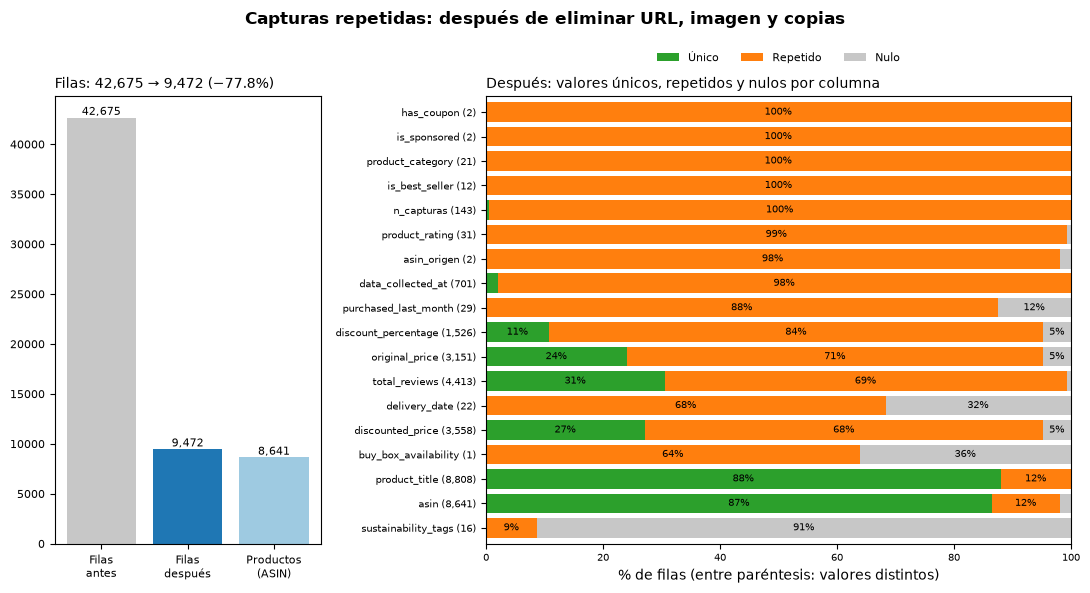

In [32]:
df1 = df1.drop(columns=["product_page_url", "product_image_url"])
comparar = [c for c in df1.columns if c not in ("data_collected_at", "delivery_date")]
antes = len(df1)
df1 = df1.sort_values("data_collected_at", kind="stable")
df1["n_capturas"] = df1.groupby(comparar, dropna=False)["data_collected_at"].transform("size")
df1 = df1.drop_duplicates(subset=comparar).sort_index().reset_index(drop=True)
print(f"Filas eliminadas: {antes - len(df1):,} | quedan: {len(df1):,} | ASIN únicos: {df1['asin'].nunique():,} | "
      f"repetidas que quedan: {df1.duplicated(subset=comparar).sum()}")

# Gráfico después: cantidad de filas y % de valores únicos, repetidos y nulos por columna (cada barra suma 100%)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 6), gridspec_kw={"width_ratios": [1, 2.2]})
filas = pd.Series({"Filas\nantes": antes, "Filas\ndespués": len(df1), "Productos\n(ASIN)": df1["asin"].nunique()})
ax1.bar(filas.index, filas, color=["#c7c7c7", "#1f77b4", "#9ecae1"])
ax1.bar_label(ax1.containers[0], fmt="{:,.0f}", fontsize=8)
ax1.set_title(f"Filas: {antes:,} → {len(df1):,} (−{1 - len(df1) / antes:.1%})", fontsize=10, loc="left")
ax1.tick_params(labelsize=8)

nulo = df1.isna().mean() * 100
repetido = df1.apply(lambda s: s.dropna().duplicated(keep=False).sum()) / len(df1) * 100
pct = pd.DataFrame({"Único": 100 - repetido - nulo, "Repetido": repetido, "Nulo": nulo}).sort_values("Repetido")
pct.index = [f"{c} ({df1[c].nunique():,})" for c in pct.index]
pct.plot.barh(stacked=True, ax=ax2, width=0.8, color=["#2ca02c", "#ff7f0e", "#c7c7c7"])
for barras, col in zip(ax2.containers, pct.columns):                     # % dentro de cada tramo (se omite si < 3%)
    ax2.bar_label(barras, labels=[f"{v:.0f}%" if v >= 3 else "" for v in pct[col]], label_type="center", fontsize=7)
ax2.set(xlim=(0, 100), xlabel="% de filas (entre paréntesis: valores distintos)")
ax2.set_title("Después: valores únicos, repetidos y nulos por columna", fontsize=10, loc="left")
ax2.tick_params(labelsize=7)
ax2.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.05), frameon=False, fontsize=8)
fig.suptitle("Capturas repetidas: después de eliminar URL, imagen y copias", fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURAS / "13_capturas_repetidas_antes_despues.png", dpi=200)
plt.show()

### Paso 20 -- Revisión final y guardado

`info()` muestra, por columna, cuántos valores no vacíos tiene y su tipo (`float64` = decimal, `Int64`/`int64` = entero, `datetime64` = fecha, `str` = texto).

Se guardan estos archivos:
- `data/procesado/amazon_electronics_cleaned_with_asin.csv`: dataset limpio con `asin` y `asin_origen`.
- `data/procesado/asin_pendientes_validacion.csv`: trazabilidad de los ASIN validados a mano.

In [33]:
df1.info()

df1.to_csv(PROCESADO / "amazon_electronics_cleaned_with_asin.csv", index=False, encoding="utf-8-sig")
asin_pendientes_validacion.to_csv(PROCESADO / "asin_pendientes_validacion.csv", index=False, encoding="utf-8-sig")

sin_asin = df1.loc[df1["asin"].isna(), "product_title"].value_counts()
print(f"\nGuardado: {len(df1):,} filas | cobertura de ASIN {df1['asin'].notna().mean():.1%} | "
      f"{len(sin_asin):,} títulos aún sin ASIN ({sin_asin.sum():,} filas)")
print(sin_asin.head(5).to_string())

<class 'pandas.DataFrame'>
RangeIndex: 9472 entries, 0 to 9471
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   product_title         9472 non-null   str           
 1   product_rating        9404 non-null   float64       
 2   total_reviews         9404 non-null   float64       
 3   purchased_last_month  8289 non-null   Int64         
 4   discounted_price      9023 non-null   float64       
 5   original_price        9023 non-null   float64       
 6   is_best_seller        9472 non-null   str           
 7   is_sponsored          9472 non-null   int64         
 8   has_coupon            9472 non-null   int64         
 9   buy_box_availability  6056 non-null   str           
 10  delivery_date         6470 non-null   datetime64[us]
 11  sustainability_tags   826 non-null    str           
 12  data_collected_at     9472 non-null   datetime64[us]
 13  discount_percentage   9023 no